# TOJ Preprocessing 

**List of Contents:** \
1- Baseline preprocessing for psychometric characterization \
2- Prior stimulus preprocessing\
3- Prior response preprocessing

In [1]:
library(tidyverse)
library(ggpubr)
library(rstatix)
library(readxl)
library(dplyr)
library(broom)
library(openxlsx)
library(DEoptim)
library(writexl)

Warning message:
"package 'ggplot2' was built under R version 4.4.3"
── Attaching core tidyverse packages ──────────────────────────────────────────────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.1.4     ✔ readr     2.1.5
✔ forcats   1.0.0     ✔ stringr   1.5.1
✔ ggplot2   4.0.3     ✔ tibble    3.2.1
✔ lubridate 1.9.3     ✔ tidyr     1.3.1
✔ purrr     1.0.2     
── Conflicts ────────────────────────────────────────────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors

Attaching package: 'rstatix'


The following object is masked from 'package:stats':

    filter


Warning message:
"package 'openxlsx' was built under R version 4.4.3"
Warning message:
"package 'DEoptim' was built under R version 4.4.3"
Loading required package: parallel


DEoptim package
Differential Evolution algorithm in 

###############################################################\
###############################################################
# 1 Baseline preprocessing for psychometric characterization

**List of Contents:** \
1-1 Load raw datasets from the two TOJ experimental sessions and merge them into a single dataset \
1-2 Remove trials that should not be included in the analysis \
1-3 Participant level preprocessing with psychometric fits

###############################################################
## 1-1 Load raw datasets from the two TOJ experimental sessions and merge them into a single dataset

In [139]:
# Set the directory where your Excel files are located
setwd("data/TOJ_1/")

# List all Excel files in the directory
files <- list.files(pattern = "*.csv")
# Create an empty data frame to store the merged data
data1 <- data.frame()

# Loop through each file and read the desired columns into merged_data
for (file in files) {
  print(file)
  # Read the Excel file
  data <-  read.csv(file)
  
  # Select the desired columns (replace "column1" and "column2" with your actual column names)
  selected_columns <- data[c("participant","TrialType", "button_resp_3.keys","button_resp_3.rt")]
  
  # Append selected_columns to merged_data
  data1 <- rbind(data1, selected_columns)
}

# Recode button responses into perceptual reports
# 'v' = visual first
# 'a' = auditory first
data1$resp <- ifelse(data1$button_resp_3.keys == 0, "v", NA)
data1$resp[data1$button_resp_3.keys == 2] <- "a"

setwd("..")
setwd("..")

[1] " P01_TOJ1.csv"
[1] " P02_TOJ1.csv"
[1] " P03_TOJ1.csv"
[1] " P04_TOJ1.csv"
[1] " P05_TOJ1.csv"
[1] " P06_TOJ1.csv"
[1] " P07_TOJ1.csv"
[1] " P08_TOJ1.csv"
[1] " P09_TOJ1.csv"
[1] " P10_TOJ1.csv"
[1] " P11_TOJ1.csv"


In [140]:
# Set the directory where your Excel files are located
setwd("data/TOJ_2/")

# List all Excel files in the directory
files <- list.files(pattern = "*.csv")
# Create an empty data frame to store the merged data
data2 <- data.frame()

# Loop through each file and read the desired columns into merged_data
for (file in files) {
  print(file)
  # Read the Excel file
  data <-  read.csv(file)
  
  # Select the desired columns (replace "column1" and "column2" with your actual column names)
  selected_columns <- data[c("participant","TrialType", "button_resp_3.keys","button_resp_3.rt")]
  
  # Append selected_columns to merged_data
  data2 <- rbind(data2, selected_columns)
}

# Recode button responses into perceptual reports
# 'v' = visual first
# 'a' = auditory first
data2$resp <- ifelse(data2$button_resp_3.keys == 2, "v", NA)
data2$resp[data2$button_resp_3.keys == 0] <- "a"

setwd("..")
setwd("..")

[1] " P12_TOJ2.csv"
[1] " P13_TOJ2.csv"
[1] " P14_TOJ2.csv"
[1] " P15_TOJ2.csv"
[1] " P16_TOJ2.csv"
[1] " P17_TOJ2.csv"
[1] " P18_TOJ2.csv"
[1] " P19_TOJ2.csv"
[1] " P20_TOJ2.csv"
[1] " P21_TOJ2.csv"
[1] " P22_TOJ2.csv"


In [141]:
# Merge datasets
data <- bind_rows(data1, data2)

# exclude training session
data <- data %>% group_by(participant) %>% filter(1:n() >max(which(TrialType=='')[which(TrialType=='')<100])) %>% ungroup()

# exclude unneeded rows
data <- data[data$TrialType!='',]

data <- data %>%
  select(participant, TrialType, resp, button_resp_3.rt)
colnames(data)[4] <- "rt"

In [142]:
unique(data$participant)

[1]  2  4  6  8  9 10 12 13 18 20 22  1  3  5  7 11 14 15 16 17 19 21

In [143]:
unique(data$TrialType)

[1] "audiovisual_SOA_40"   "audiovisual_SOA_200"  "audiovisual_NSOA_80" 
 [4] "audiovisual_SOA_20"   "audiovisual_SOA_120"  "audiovisual_SOA_100" 
 [7] "audiovisual_SOA_0"    "audiovisual_NSOA_150" "audiovisual_NSOA_120"
[10] "audiovisual_NSOA_20"  "visual_only"          "audiovisual_SOA_250" 
[13] "audiovisual_NSOA_400" "audiovisual_NSOA_100" "audiovisual_SOA_300" 
[16] "audiovisual_NSOA_40"  "audiovisual_NSOA_300" "audiovisual_SOA_150" 
[19] "catch"                "audiovisual_SOA_60"   "auditroy_only"       
[22] "audiovisual_NSOA_250" "audiovisual_SOA_400"  "audiovisual_SOA_80"  
[25] "audiovisual_NSOA_60"  "audiovisual_NSOA_200"

In [144]:
unique(data$resp)

[1] "a" "v" NA

In [145]:
n_participants <- length(unique(data$participant))
n_participants

[1] 22

In [146]:
n_type <- length(unique(data$TrialType))
n_type

[1] 26

In [147]:
nrow(data)

[1] 17160

In [148]:
n_type * n_participants * 30

[1] 17160

In [149]:
write.xlsx(data, "files/TOJ_data.xlsx", rowNames = FALSE)

###############################################################
## 1-2 Remove trials that should not be included in the analysis

- remove catch trials
- remove missing responses
- remove anticipatory responses (RT < 100 ms)
- remove RT outliers
- remove unimodal trials

In [107]:
nrow(data)

[1] 17160

In [108]:
# remove catch trials
n_current <- nrow(data)
data <- data %>% filter(TrialType != "catch")
n_filtered <- n_current - nrow(data)
print(paste('number of deleted datapoints: ', n_filtered, "     number of remaining datapoints: ", nrow(data)))

[1] "number of deleted datapoints:  660      number of remaining datapoints:  16500"


In [109]:
(n_type-1) * n_participants * 30

[1] 16500

In [110]:
# filter nonresponses
n_current <- nrow(data)
data <- data %>% filter(!is.na(resp))
n_filtered <- n_current - nrow(data)
print(paste('number of deleted datapoints: ', n_filtered, "     number of remaining datapoints: ", nrow(data)))

[1] "number of deleted datapoints:  0      number of remaining datapoints:  16500"


In [111]:
#  remove anticipatory responses (RT < 100 ms)
n_current <- nrow(data)
data <- data %>%
  filter(rt >= 0.1)
n_filtered <- n_current - nrow(data)
print(paste('number of deleted datapoints: ', n_filtered, "     number of remaining datapoints: ", nrow(data)))

[1] "number of deleted datapoints:  3      number of remaining datapoints:  16497"


In [112]:
#  Remove Trials outside ±2.5 SD from the mean RT are removed
n_current <- nrow(data)
data <- data %>%

  group_by(participant, TrialType) %>%
    filter(
    rt > mean(rt) - 2.5*sd(rt),
    rt < mean(rt) + 2.5*sd(rt)
  ) %>%
    ungroup()
n_filtered <- n_current - nrow(data)
print(paste('number of deleted datapoints: ', n_filtered, "     number of remaining datapoints: ", nrow(data)))

[1] "number of deleted datapoints:  543      number of remaining datapoints:  15954"


In [113]:
## Compute participant-level response proportions for each SOA condition
df <- data %>%
  group_by(participant, TrialType) %>%
  summarise(
    visual_first = mean(resp == "v"),
    mean_rt = mean(rt),
    n_trials = n(),
    .groups = "drop"
  )
head(df)

participant,TrialType,visual_first,mean_rt,n_trials
<int>,<chr>,<dbl>,<dbl>,<int>
1,audiovisual_NSOA_100,0.6785714,2.121258,28
1,audiovisual_NSOA_120,0.3793103,1.899485,29
1,audiovisual_NSOA_150,0.5862069,2.103462,29
1,audiovisual_NSOA_20,0.4137931,1.908720,29
1,audiovisual_NSOA_200,0.3103448,1.889679,29
1,audiovisual_NSOA_250,0.1034483,1.788838,29


In [114]:
nrow(df)

[1] 550

In [115]:
(n_type-1)*n_participants

[1] 550

In [116]:
min(df$n_trials)

[1] 27

In [117]:
df %>%
  filter(TrialType %in% c("auditroy_only", "visual_only")) 

participant,TrialType,visual_first,mean_rt,n_trials
<int>,<chr>,<dbl>,<dbl>,<int>
1,auditroy_only,0.00000000,1.3415923,30
1,visual_only,1.00000000,1.3478709,28
2,auditroy_only,0.10714286,1.6194831,28
2,visual_only,0.92857143,1.5645421,28
3,auditroy_only,0.00000000,1.0716164,30
3,visual_only,1.00000000,1.2620689,28
4,auditroy_only,0.48275862,1.2322516,29
4,visual_only,0.48275862,1.4097808,29
5,auditroy_only,0.00000000,0.7206368,30


In [118]:
#  Remove unimodal trials 
n_current <- nrow(data)
data <- data %>%
  filter(!TrialType %in% c("auditroy_only", "visual_only"))

n_filtered <- n_current - nrow(data)
print(paste('number of deleted datapoints: ', n_filtered, "     number of remaining datapoints: ", nrow(data)))

[1] "number of deleted datapoints:  1273      number of remaining datapoints:  14681"


In [119]:
df <- df %>%
  filter(!TrialType %in% c("auditroy_only", "visual_only"))

###############################################################
## 1-3 Participant level preprocessing with psychometric fits

In [120]:
## Map each trial condition to its corresponding SOA value
## Negative values indicate auditory-leading trials
## Positive values indicate visual-leading trials

trial_labels <- c(
'audiovisual_NSOA_100','audiovisual_NSOA_120','audiovisual_NSOA_150','audiovisual_NSOA_20',
'audiovisual_NSOA_200','audiovisual_NSOA_250','audiovisual_NSOA_300','audiovisual_NSOA_40',
'audiovisual_NSOA_400','audiovisual_NSOA_60','audiovisual_NSOA_80',
'audiovisual_SOA_0',
'audiovisual_SOA_100','audiovisual_SOA_120','audiovisual_SOA_150','audiovisual_SOA_20',
'audiovisual_SOA_200','audiovisual_SOA_250','audiovisual_SOA_300','audiovisual_SOA_40',
'audiovisual_SOA_400','audiovisual_SOA_60','audiovisual_SOA_80'
)

soa_values <- c(
-100,-120,-150,-20,-200,-250,-300,-40,-400,-60,-80,
0,
100,120,150,20,200,250,300,40,400,60,80
)

soa_map <- data.frame(
  TrialType = trial_labels,
  SOA = soa_values
)

data <- left_join(data, soa_map)
df <- left_join(df, soa_map)

head(data)

Joining with `by = join_by(TrialType)`
Joining with `by = join_by(TrialType)`


participant,TrialType,resp,rt,SOA
<int>,<chr>,<chr>,<dbl>,<dbl>
2,audiovisual_SOA_40,a,2.1725643,40
2,audiovisual_SOA_200,a,2.6904939,200
2,audiovisual_NSOA_80,v,1.3538908,-80
2,audiovisual_SOA_20,v,2.4231556,20
2,audiovisual_SOA_120,v,2.4231909,120
2,audiovisual_SOA_100,v,0.8193423,100


In [121]:
# check if the data has an increasing trend
linear_results <- data.frame()
for (par in unique(df$participant)) {
    df_subset <- df %>% filter(participant == par)
    fit <- lm(visual_first ~ SOA, data = df_subset)
    linear_results <- rbind(linear_results, data.frame(
            participant = par,
            p = summary(fit)$coefficients[2,4]))
        
}

In [122]:
linear_results %>% arrange(p)

participant,p
<int>,<dbl>
13,4.271886e-13
19,4.230570e-12
21,1.202628e-11
12,1.652460e-11
8,2.710120e-11
15,3.340619e-11
3,4.330555e-11
7,4.488252e-11
22,5.982768e-11


In [123]:
###############################################################
# Fit Gaussian function to synchorony responses
#
# Model:
# p(SOA) = 1 / (1 + (1/3)^(SOA/jnd-pss/jnd))
#
# Parameters:
# pss = Point of Subjective Simultaneity
# jnd = Just Noticeable Difference
###############################################################

Gauss <- function(data){

  loss_function <- function(params){
    pss <- params[1]
    jnd <- params[2]
    predicted <-  1 / (1 + (1/3)^(data$SOA/jnd-pss/jnd))
    sum((predicted - data$visual_first)^2)
  }

  DEoptim(
    loss_function,
    lower = c(-500, .001),
    upper = c(400, 1000)
  )
}

psy_results <- data.frame()

for(subj in unique(df$participant)){
  subdata <- df %>% filter(participant == subj)
  fit <- Gauss(subdata)$optim$bestmem
  psy_results <- rbind(
    psy_results,
    data.frame(
      participant = subj,
      pss = fit[1],
      jnd = fit[2]
    )
  )
}

rownames(psy_results) <- NULL

Iteration: 1 bestvalit: 0.451870 bestmemit: -127.870349  216.079100
Iteration: 2 bestvalit: 0.380852 bestmemit:  -20.197780  217.006239
Iteration: 3 bestvalit: 0.380852 bestmemit:  -20.197780  217.006239
Iteration: 4 bestvalit: 0.351851 bestmemit:  -96.126299  202.722120
Iteration: 5 bestvalit: 0.295112 bestmemit:  -46.752998  186.918054
Iteration: 6 bestvalit: 0.285416 bestmemit:  -46.752998  176.176327
Iteration: 7 bestvalit: 0.280335 bestmemit:  -61.148362  162.178052
Iteration: 8 bestvalit: 0.278223 bestmemit:  -50.858539  163.720960
Iteration: 9 bestvalit: 0.278223 bestmemit:  -50.858539  163.720960
Iteration: 10 bestvalit: 0.278223 bestmemit:  -50.858539  163.720960
Iteration: 11 bestvalit: 0.278085 bestmemit:  -52.243188  164.318540
Iteration: 12 bestvalit: 0.278085 bestmemit:  -52.243188  164.318540
Iteration: 13 bestvalit: 0.277893 bestmemit:  -52.060962  161.008618
Iteration: 14 bestvalit: 0.277880 bestmemit:  -52.392089  160.676794
Iteration: 15 bestvalit: 0.277880 bestmemit

In [124]:
head(psy_results)

,participant,pss,jnd
,<int>,<dbl>,<dbl>
1,1,-53.211248,161.6654
2,2,-271.896665,461.7843
3,3,-51.552291,141.9164
4,4,-239.453193,1000.0000
5,5,-102.716938,124.7084
6,6,-8.006722,228.9453


In [125]:
nrow(psy_results)

[1] 22

In [126]:
sort(psy_results$pss)

[1] -500.0000000 -271.8966650 -239.4531930 -172.8047316 -133.0591838
 [6] -119.1589871 -106.0308448 -102.7169378  -91.3363910  -53.2112476
[11]  -51.5522909  -35.5157771  -27.0509439  -15.7222048   -8.0067223
[16]   -4.9121986   -0.9154361    2.2978647    2.4275636   42.8992929
[21]  100.1841004  140.1972587

In [127]:
sort(psy_results$jnd)

[1]   45.61007   65.51637   73.96208   81.49649   84.48921   93.97794
 [7]  119.34113  122.38215  124.70841  131.58924  140.89484  141.91639
[13]  145.73190  149.73078  161.66543  170.30996  177.48903  228.94529
[19]  294.03968  336.60415  461.78432 1000.00000

In [128]:
psy_results  %>% filter(pss< -200)

participant,pss,jnd
<int>,<dbl>,<dbl>
2,-271.8967,461.78432
4,-239.4532,1000.00000
16,-500.0000,45.61007


In [129]:
psy_results  %>% filter(pss> 100)

participant,pss,jnd
<int>,<dbl>,<dbl>
11,100.1841,294.03968
17,140.1973,65.51637


In [130]:
psy_results %>% filter(jnd > 200) %>% arrange(jnd)

participant,pss,jnd
<int>,<dbl>,<dbl>
6,-8.006722,228.9453
11,100.184100,294.0397
18,-133.059184,336.6042
2,-271.896665,461.7843
4,-239.453193,1000.0000


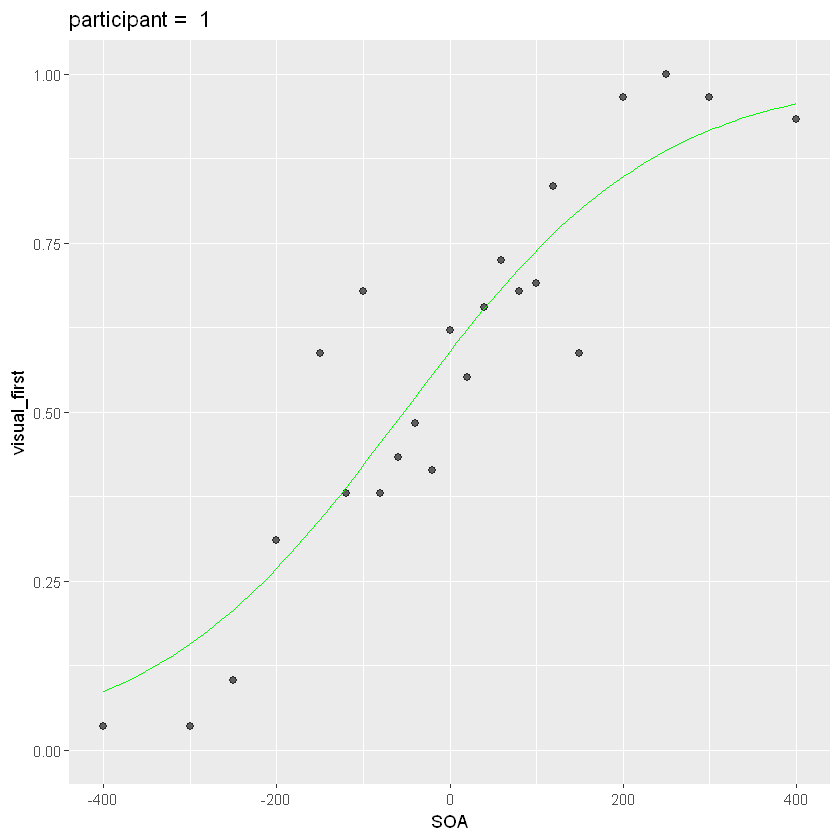

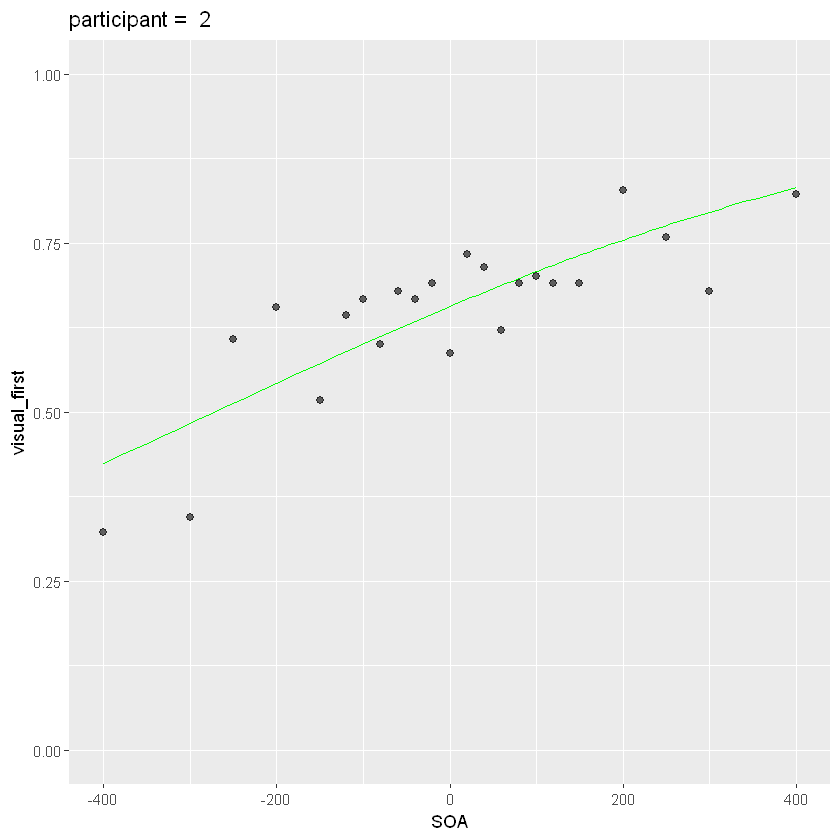

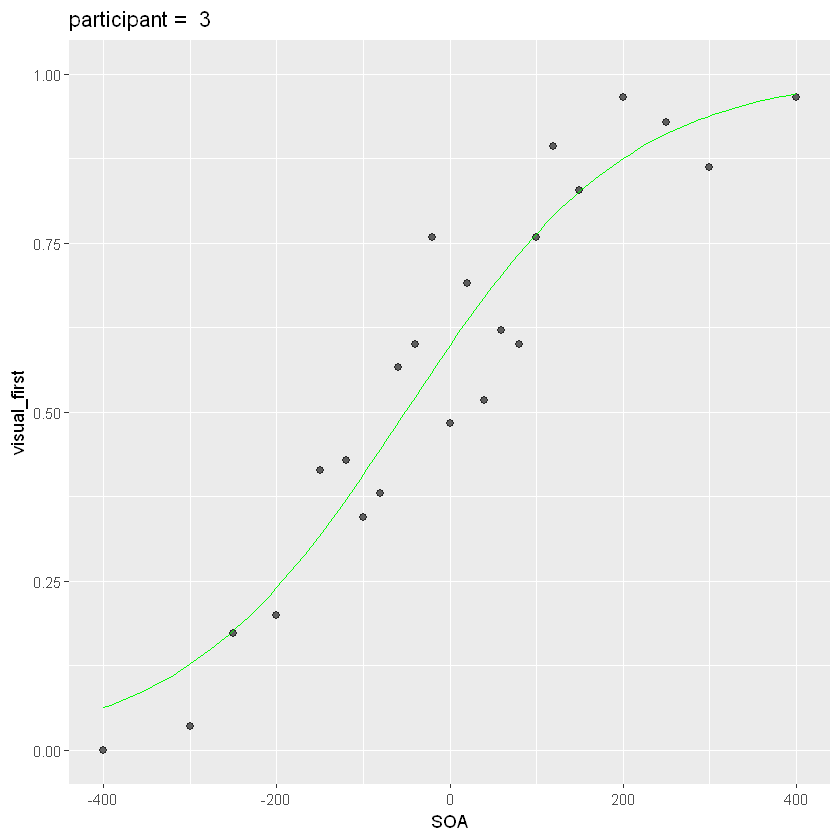

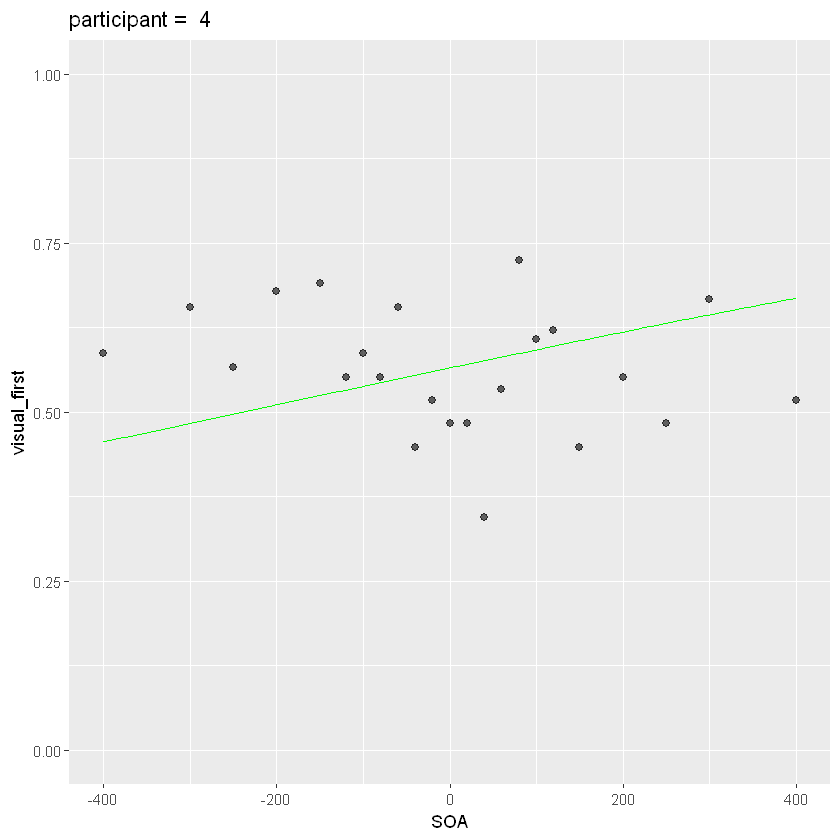

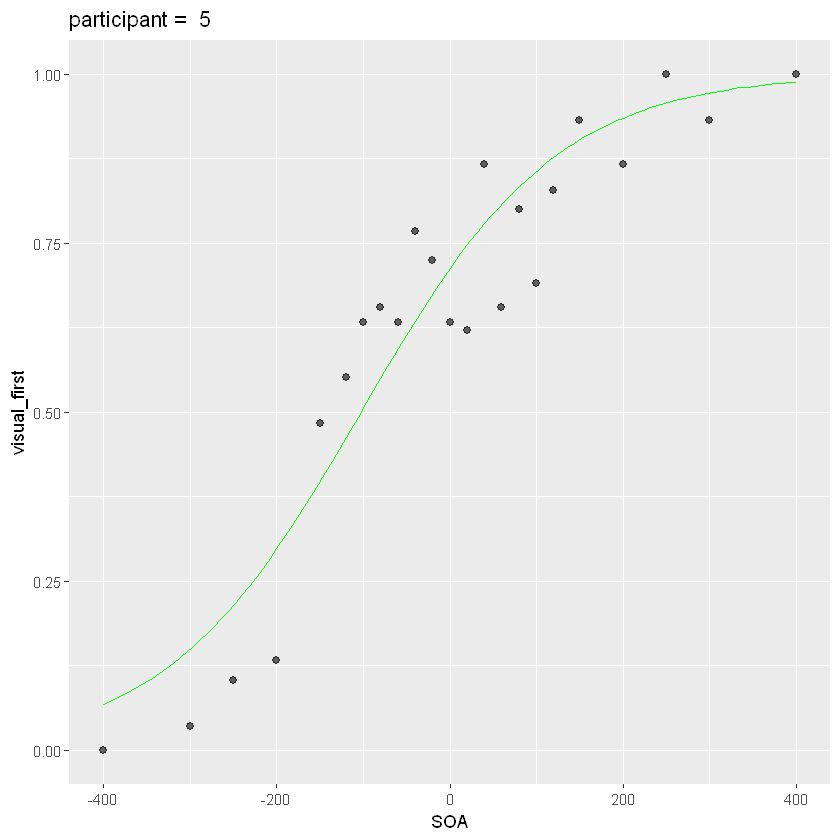

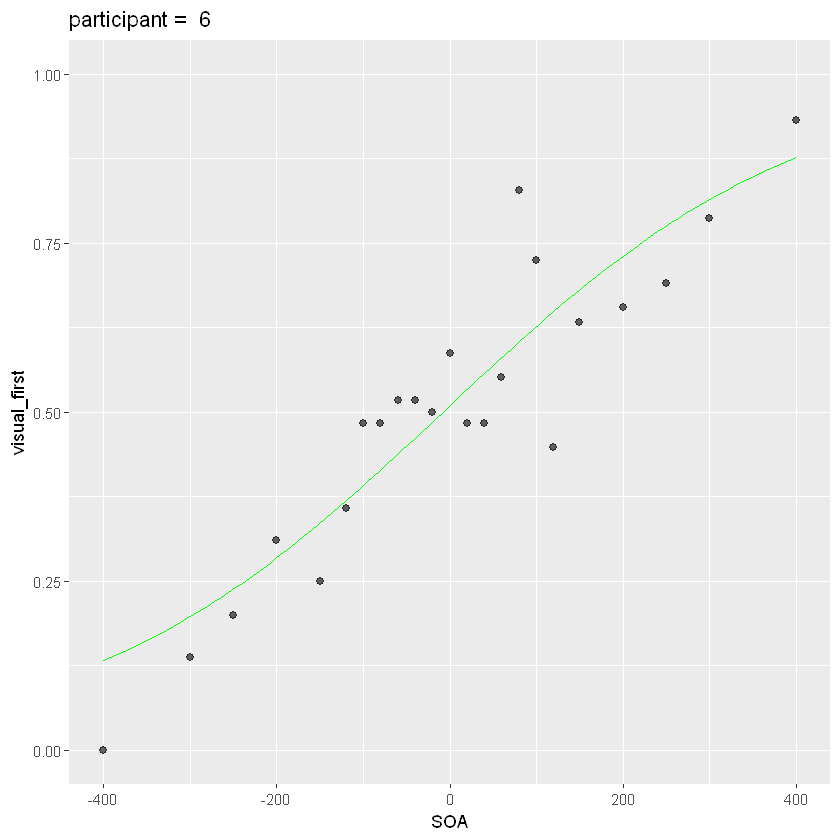

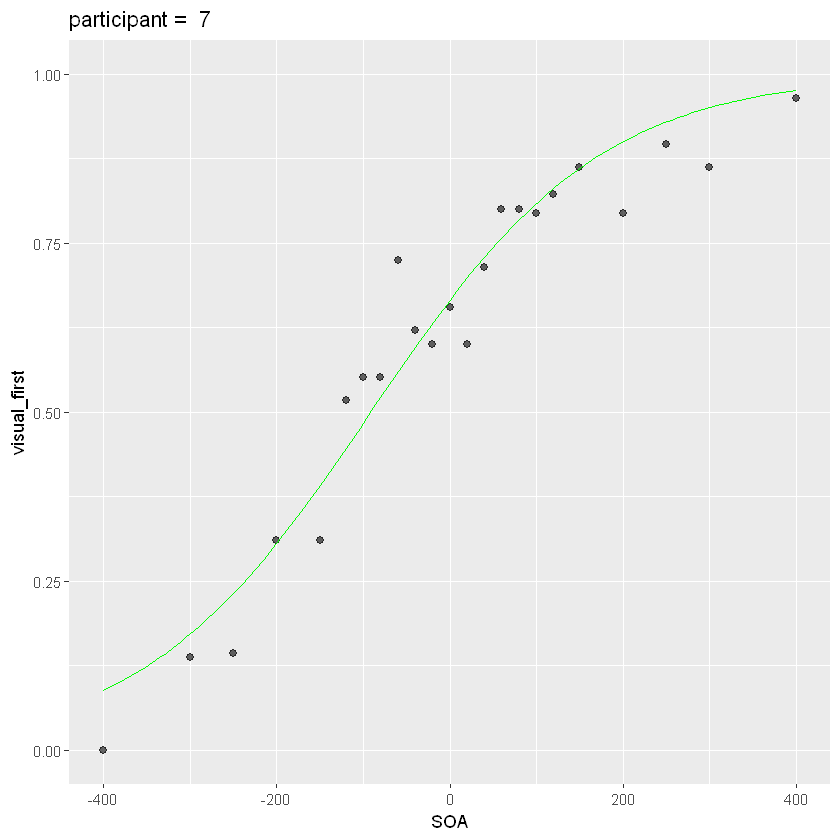

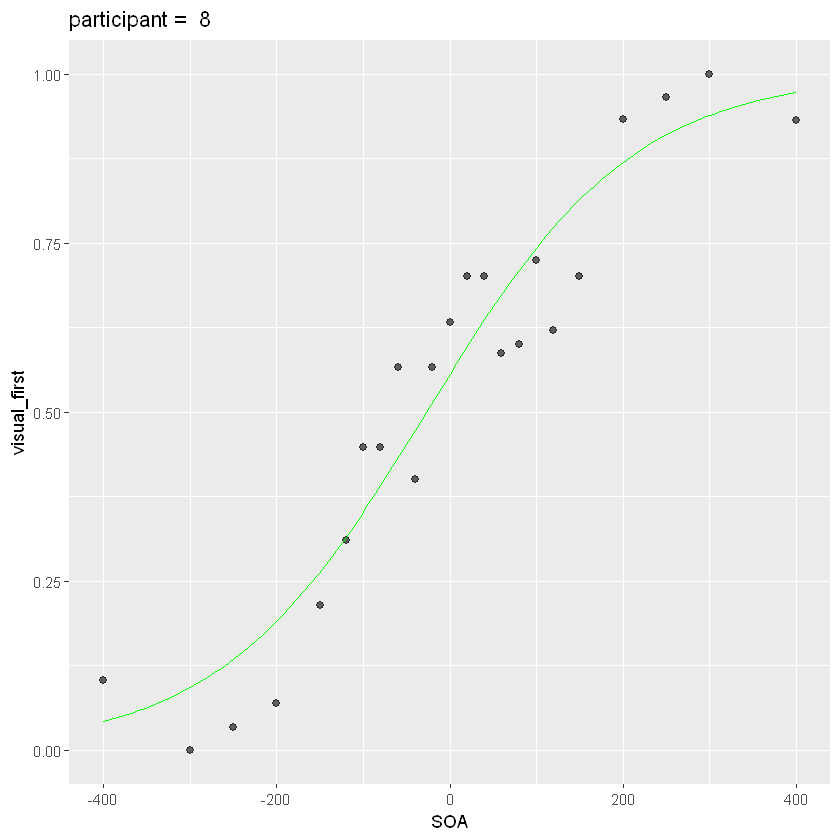

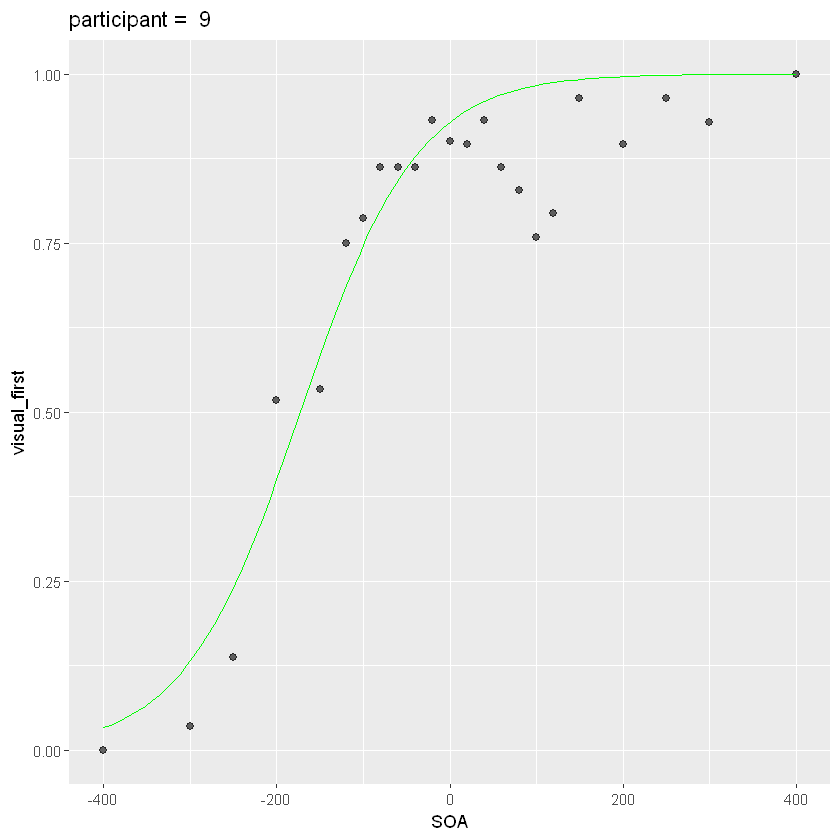

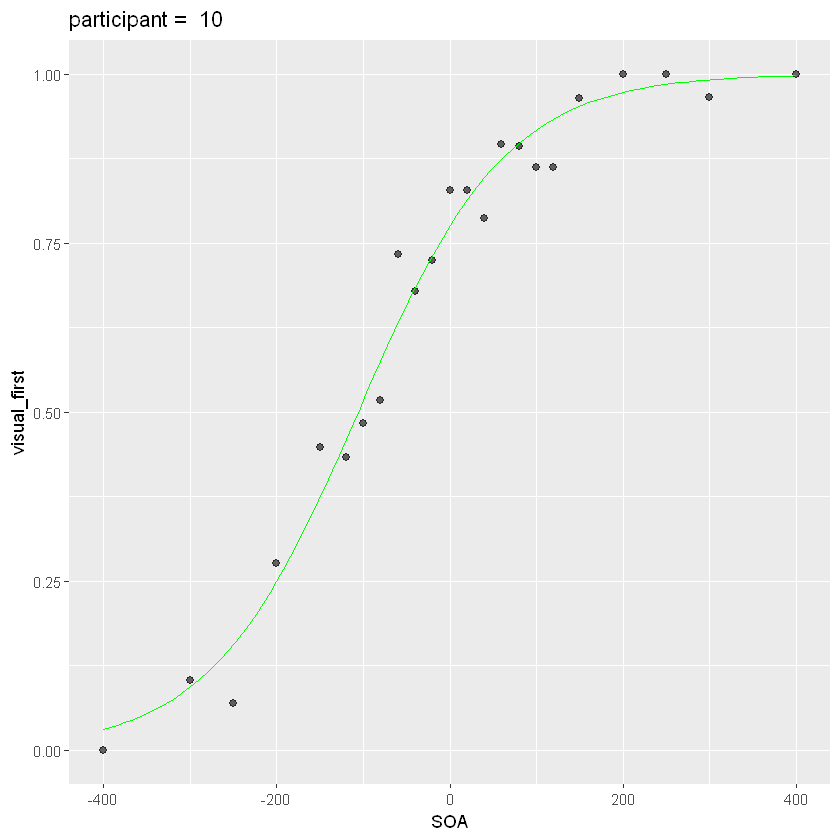

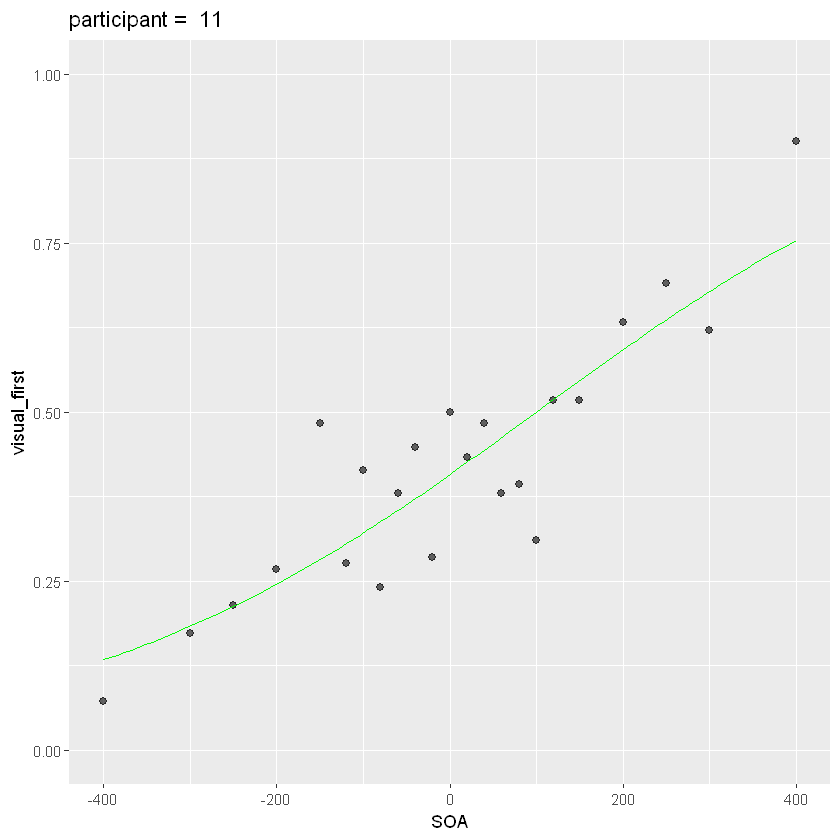

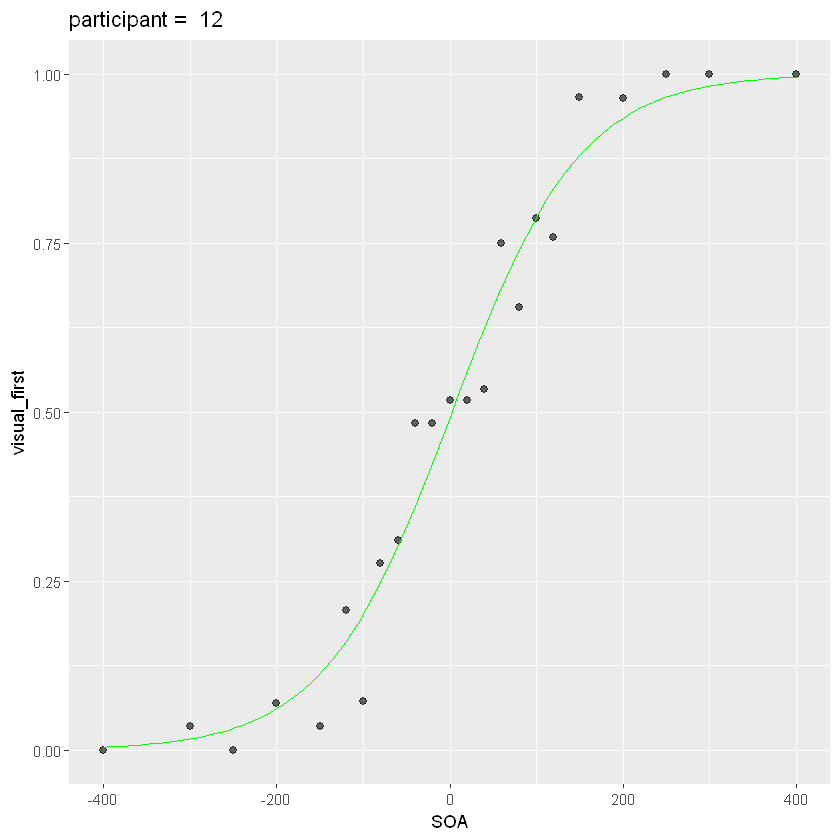

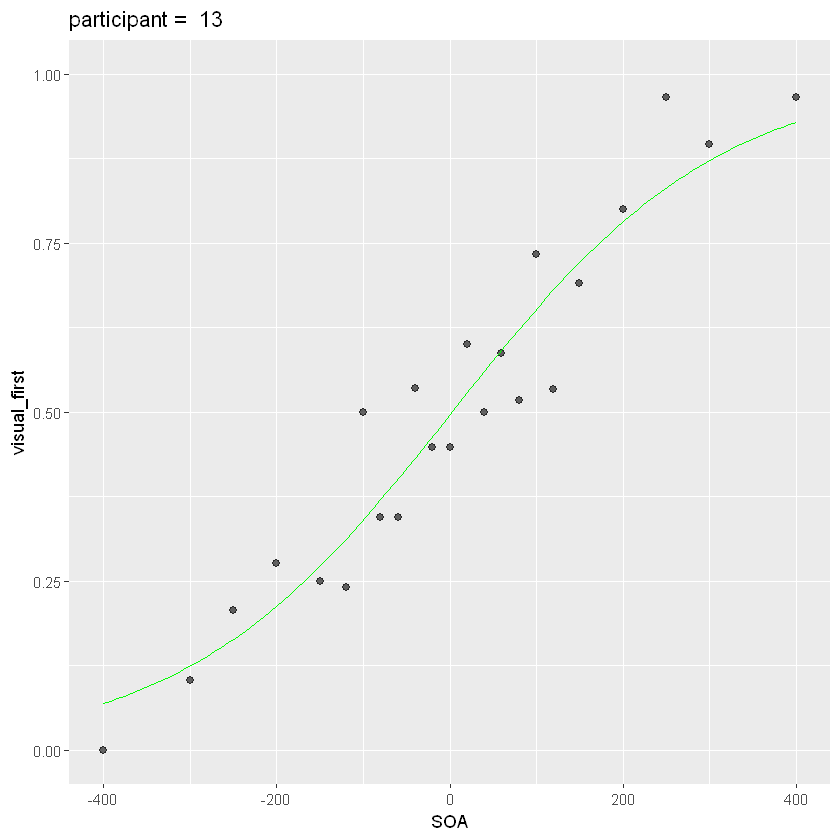

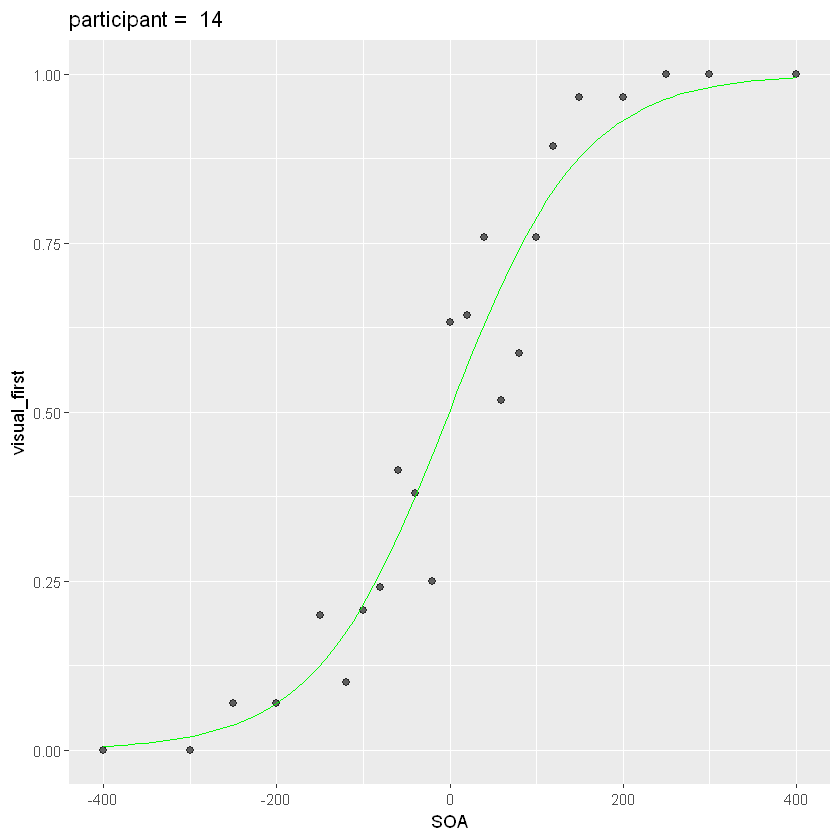

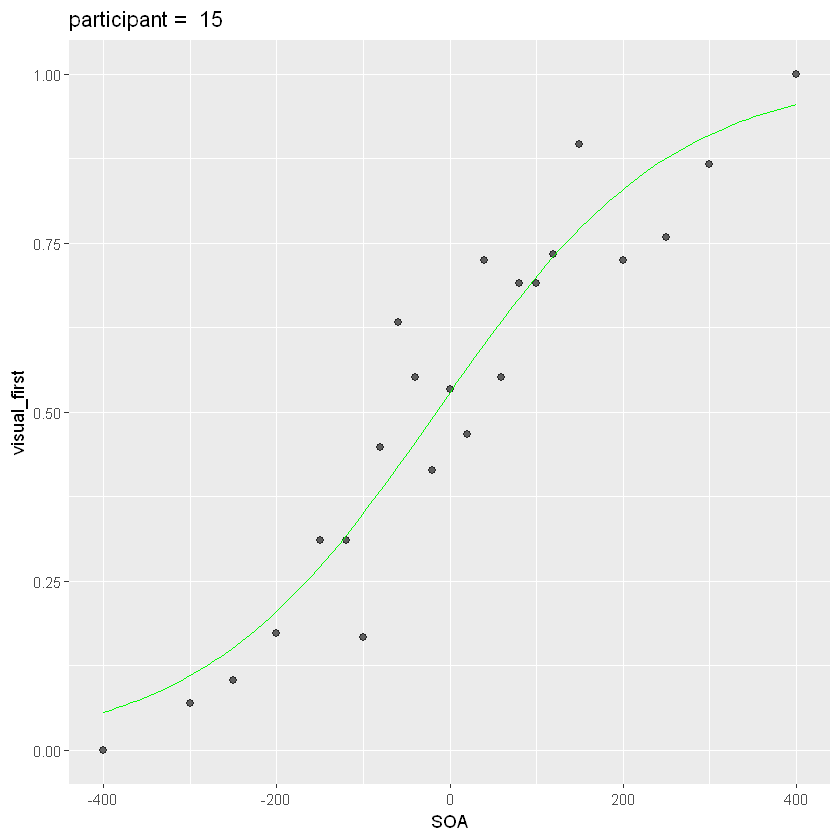

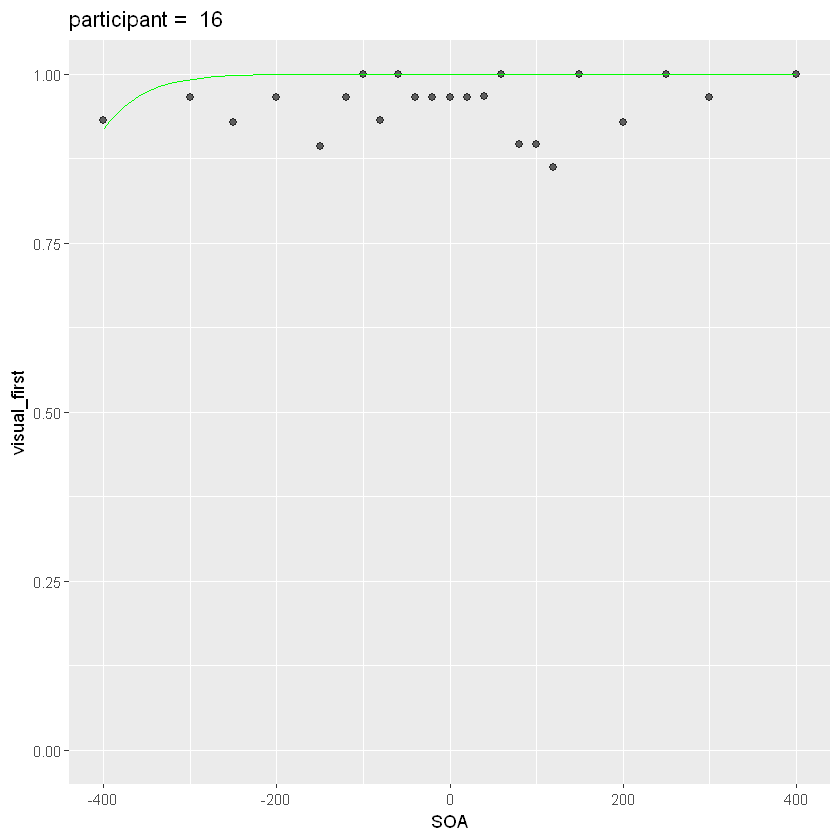

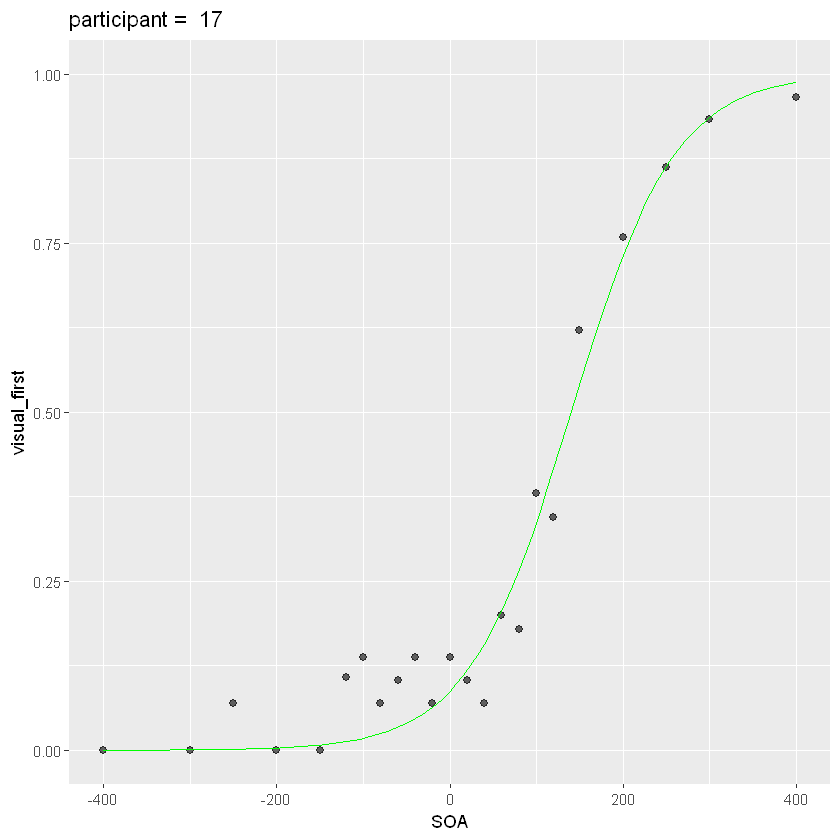

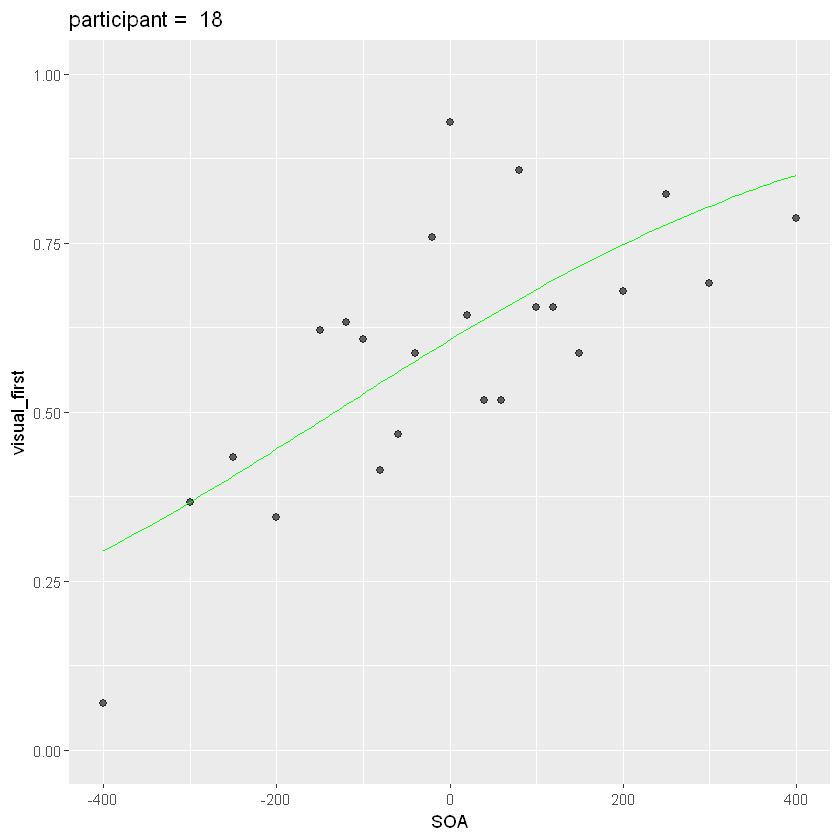

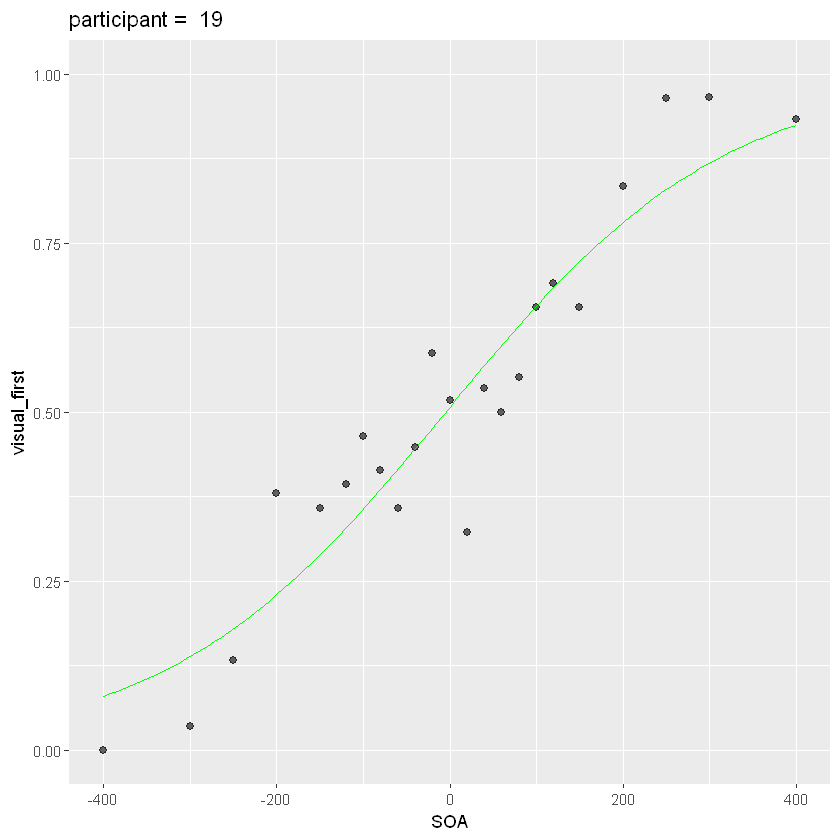

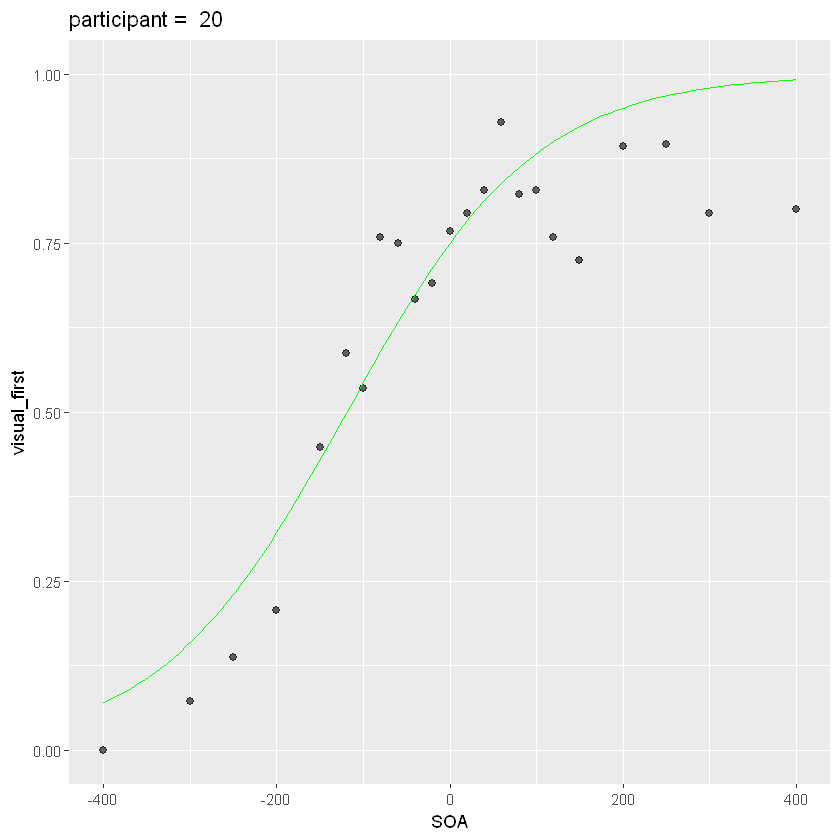

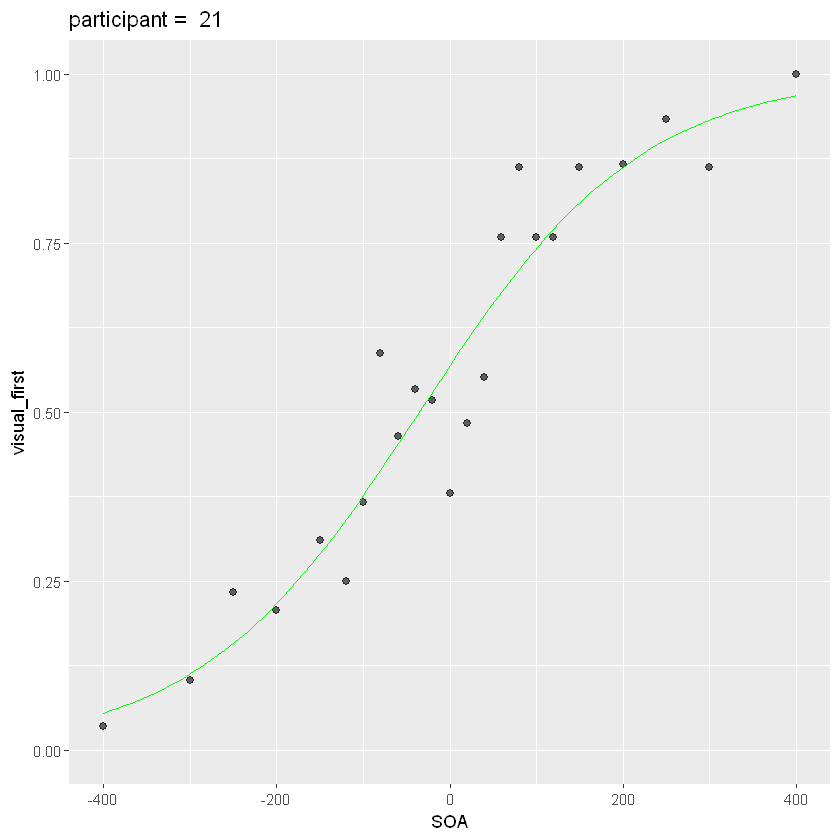

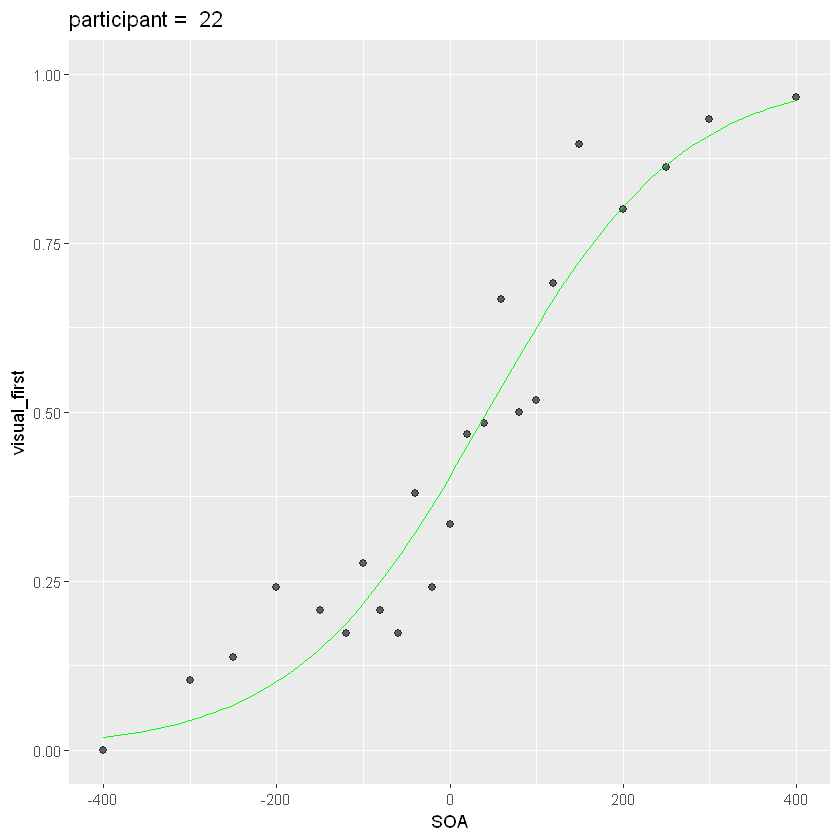

In [131]:
ff <- function(x,pss,jnd){
    1 / (1 + (1/3)^(x/jnd-pss/jnd))
}
for (par in unique(df$participant)) {
    df_subset <- df %>% filter(participant == par)
    print(ggplot(df_subset, aes(x = SOA, y = visual_first)) +
        geom_point(size = 2, alpha = 0.6) +
        geom_function(fun=ff, args = list(pss = psy_results$pss[psy_results$participant == par], jnd = psy_results$jnd[psy_results$participant == par]), color='green') +
        labs(title = paste('participant = ',par)) + ylim(0,1))
}

In [135]:
## Compute coefficient of determination (R²) to evaluate the goodness-of-fit of the psychometric model

R2 <- function(observed, predicted){
  SS_res <- sum((observed - predicted)^2)
  SS_tot <- sum((observed - mean(observed))^2)
  return(1 - SS_res / SS_tot)
}

psy_results$R2 <- NA

for(i in 1:nrow(psy_results)){
  subj <- psy_results$participant[i]
  subdata <- df %>% filter(participant == subj)
  pred <- 1 / (1 + (1/3)^(subdata$SOA/psy_results$jnd[i]-psy_results$pss[i]/psy_results$jnd[i]))
  psy_results$R2[i] <- R2(subdata$visual_first, pred)
}

In [136]:
psy_results %>% arrange(R2)

participant,pss,jnd,R2
<int>,<dbl>,<dbl>,<dbl>
16,-500.0000000,45.61007,-1.1896024
4,-239.4531930,1000.00000,-0.5862516
18,-133.0591838,336.60415,0.5368785
2,-271.8966650,461.78432,0.6745948
11,100.1841004,294.03968,0.7739537
6,-8.0067223,228.94529,0.8311183
1,-53.2112476,161.66543,0.8414178
20,-119.1589871,119.34113,0.8580178
19,-4.9121986,177.48903,0.8846412


In [137]:
# Exclude participants with poor psychometric fits
n_current <- nrow(data)
data <- data[!(data$participant %in% c(2,4,16,18)),]
n_filtered <- n_current - nrow(data)
print(paste('number of deleted datapoints: ', n_filtered, "     number of remaining datapoints: ", nrow(data)))

[1] "number of deleted datapoints:  2663      number of remaining datapoints:  12018"


In [138]:
data <- data %>% arrange(participant, SOA)
data <- data[c(1,5,3,4)]
head(data)

participant,SOA,resp,rt
<int>,<dbl>,<chr>,<dbl>
1,-400,a,1.788303
1,-400,a,1.537577
1,-400,a,1.554352
1,-400,a,1.353832
1,-400,a,1.504235
1,-400,a,1.771497


In [220]:
write.xlsx(data, "files/TOJ_general_data.xlsx", rowNames = FALSE)

###############################################################\
###############################################################
# 2 Prior stimulus preprocessing

- Remove outlier participants
- Remove catch trials.
- Remove unimodal trials (auditory-only, visual-only).
- Remove anticipatory responses (RT < 100 ms).
- Remove missed trials.
- Remove RT outliers (> ±2.5 SD within participant × condition).
- Remove the first trial of each mini-block.
- Remove trials following catch trials or zero-SOA trials or unimodal trials.

In [157]:
data <- read_xlsx("files/TOJ_data.xlsx")

In [158]:
head(data)

participant,TrialType,resp,rt
<dbl>,<chr>,<chr>,<dbl>
2,audiovisual_SOA_40,a,2.1725643
2,audiovisual_SOA_200,a,2.6904939
2,audiovisual_NSOA_80,v,1.3538908
2,audiovisual_SOA_20,v,2.4231556
2,audiovisual_SOA_120,v,2.4231909
2,audiovisual_SOA_100,v,0.8193423


In [159]:
n_participants = length(unique(data$participant))
n_type = length(unique(data$TrialType))

In [160]:
nrow(data)

[1] 17160

In [161]:
n_type * n_participants * 30

[1] 17160

In [162]:
###############################################################
# Remove participants with poor sigmoid model fit
###############################################################


n_current <- nrow(data)
data <- data[!(data$participant %in% c(2,4,16,18)),]
n_filtered <- n_current - nrow(data)
print(paste('number of deleted datapoints: ', n_filtered, "     number of remaining datapoints: ", nrow(data)))

[1] "number of deleted datapoints:  3120      number of remaining datapoints:  14040"


In [163]:
nrow(data)

[1] 14040

In [164]:
n_type * (n_participants-4) * 30

[1] 14040

In [165]:
### Create variables describing the previous trial stimulus
j <- data$TrialType
j <- append(j, NA, after=0)
j <- j[-c(length(j))]
data$pre_stim <- j
head(data)

participant,TrialType,resp,rt,pre_stim
<dbl>,<chr>,<chr>,<dbl>,<chr>
6,audiovisual_NSOA_150,a,1.938559,NA
6,audiovisual_NSOA_150,a,2.590482,audiovisual_NSOA_150
6,audiovisual_SOA_400,v,1.454295,audiovisual_NSOA_150
6,audiovisual_SOA_20,v,2.707251,audiovisual_SOA_400
6,audiovisual_NSOA_120,a,1.804988,audiovisual_SOA_20
6,audiovisual_SOA_300,a,2.841233,audiovisual_NSOA_120


In [166]:
###############################################################
# determine first trial of each mini-block.
# In this experiment each mini-block contains 30 trials.
# The first trial is removed because it has no valid previous-trial history.

data$pre_stim[as.numeric(row.names(data)) %% 30==1] <- NA

In [167]:
# Remove trials catch
###############################################################

n_current <- nrow(data)
data <- data[data$TrialType!='catch',]
n_filtered <- n_current - nrow(data)
print(paste('number of deleted datapoints: ', n_filtered, "     number of remaining datapoints: ", nrow(data)))

[1] "number of deleted datapoints:  540      number of remaining datapoints:  13500"


In [168]:
###############################################################
# Remove unimodal conditions (auditory-only, visual-only)
# as the analysis focuses on audiovisual temporal judgments
###############################################################

n_current <- nrow(data)
data <- data %>%
    filter(!TrialType %in% c("auditroy_only", "visual_only"))
n_filtered <- n_current - nrow(data)
print(paste('number of deleted datapoints: ', n_filtered, "     number of remaining datapoints: ", nrow(data)))

[1] "number of deleted datapoints:  1080      number of remaining datapoints:  12420"


In [169]:
(n_type-3) * (n_participants-4) * 30

[1] 12420

In [170]:
# Remove anticipatory responses (RT < 100 ms)

n_current <- nrow(data)
data <- data[data$rt>=.1,]
n_filtered <- n_current - nrow(data)
print(paste('number of deleted datapoints: ', n_filtered, "     number of remaining datapoints: ", nrow(data)))

[1] "number of deleted datapoints:  1      number of remaining datapoints:  12419"


In [171]:
# Remove missed trials

n_current <- nrow(data)
data <- data %>% filter(!is.na(resp))
n_filtered <- n_current - nrow(data)
print(paste('number of deleted datapoints: ', n_filtered, "     number of remaining datapoints: ", nrow(data)))

[1] "number of deleted datapoints:  0      number of remaining datapoints:  12419"


In [172]:
###############################################################
# Remove RT outliers within each participant × condition
# using a ±2 SD criterion
###############################################################

n_current <- nrow(data)
data <- data %>%
  group_by(participant, TrialType) %>%
  filter(
    rt < mean(rt) + 2.5*sd(rt) &
    rt > mean(rt) - 2.5*sd(rt)
  ) %>%
  ungroup()
n_filtered <- n_current - nrow(data)
print(paste('number of deleted datapoints: ', n_filtered, "     number of remaining datapoints: ", nrow(data)))

[1] "number of deleted datapoints:  401      number of remaining datapoints:  12018"


In [173]:
# Remove the first trial of each mini-block.

n_current <- nrow(data)
data <- data %>% filter(!is.na(pre_stim))
n_filtered <- n_current - nrow(data)
print(paste('number of deleted datapoints: ', n_filtered, "     number of remaining datapoints: ", nrow(data)))

[1] "number of deleted datapoints:  374      number of remaining datapoints:  11644"


In [174]:
###############################################################
# Remove trials that follow a zero-SOA or aditory_only or visual_only stimulus
###############################################################

n_current <- nrow(data)
data <- filter(data, pre_stim!= "auditroy_only")
data <- filter(data, pre_stim!= "visual_only")
data <- filter(data, pre_stim!= "audiovisual_SOA_0")
n_filtered <- n_current - nrow(data)
print(paste('number of deleted datapoints: ', n_filtered, "     number of remaining datapoints: ", nrow(data)))

[1] "number of deleted datapoints:  1348      number of remaining datapoints:  10296"


In [175]:
###############################################################
# Remove trials that follow a catch trial
###############################################################

n_current <- nrow(data)
data <- filter(data, pre_stim!='catch')
n_filtered <- n_current - nrow(data)
print(paste('number of deleted datapoints: ', n_filtered, "     number of remaining datapoints: ", nrow(data)))

[1] "number of deleted datapoints:  440      number of remaining datapoints:  9856"


In [176]:
###############################################################
# Categorize the previous stimulus as visual-leading
# or auditory-leading for serial dependence analysis
###############################################################

visual_leading_conditions <- c(
  "visual_only",
  "audiovisual_SOA_400","audiovisual_SOA_300","audiovisual_SOA_250",
  "audiovisual_SOA_200","audiovisual_SOA_150","audiovisual_SOA_120",
  "audiovisual_SOA_100","audiovisual_SOA_80","audiovisual_SOA_60",
  "audiovisual_SOA_40","audiovisual_SOA_20"
)

data <- data %>%
  mutate(
    pre_stim =
      ifelse(pre_stim %in% visual_leading_conditions,
             "visual_leading",
             "auditory_leading")
  )

In [177]:
head(data)

participant,TrialType,resp,rt,pre_stim
<dbl>,<chr>,<chr>,<dbl>,<chr>
6,audiovisual_NSOA_150,a,2.590482,auditory_leading
6,audiovisual_SOA_400,v,1.454295,auditory_leading
6,audiovisual_SOA_20,v,2.707251,visual_leading
6,audiovisual_NSOA_120,a,1.804988,visual_leading
6,audiovisual_SOA_300,a,2.841233,auditory_leading
6,audiovisual_SOA_150,v,1.136475,visual_leading


In [178]:
###############################################################
# Map TrialType to signed SOA values
###############################################################

TT <- c(
'audiovisual_NSOA_100','audiovisual_NSOA_120','audiovisual_NSOA_150','audiovisual_NSOA_20',
'audiovisual_NSOA_200','audiovisual_NSOA_250','audiovisual_NSOA_300','audiovisual_NSOA_40',
'audiovisual_NSOA_400','audiovisual_NSOA_60','audiovisual_NSOA_80',
'audiovisual_SOA_0',
'audiovisual_SOA_100','audiovisual_SOA_120','audiovisual_SOA_150','audiovisual_SOA_20',
'audiovisual_SOA_200','audiovisual_SOA_250','audiovisual_SOA_300','audiovisual_SOA_40',
'audiovisual_SOA_400','audiovisual_SOA_60','audiovisual_SOA_80'
)

SOA_vals <- c(
-100,-120,-150,-20,-200,-250,-300,-40,-400,-60,-80,
0,
100,120,150,20,200,250,300,40,400,60,80
)

soa_map <- data.frame(TrialType = TT, SOA = SOA_vals)

data <- data %>%
  filter(TrialType %in% TT) %>%
  left_join(soa_map, by = "TrialType")
data <- data %>% arrange(participant, pre_stim, SOA)
data <- data[c(1,5,6,3,4)]
head(data)

participant,pre_stim,SOA,resp,rt
<dbl>,<chr>,<dbl>,<chr>,<dbl>
1,auditory_leading,-400,a,1.537577
1,auditory_leading,-400,a,1.454046
1,auditory_leading,-400,a,1.503926
1,auditory_leading,-400,a,1.504481
1,auditory_leading,-400,a,1.069864
1,auditory_leading,-400,a,1.638146


In [250]:
write.xlsx(data, "files/TOJ_prior_stimulus_data.xlsx", rowNames = FALSE)

###############################################################\
###############################################################
# 3 Prior response preprocessing

- Remove outlier participants
- Remove catch trials.
- Remove unimodal trials (auditory-only, visual-only).
- Remove anticipatory responses (RT < 100 ms).
- Remove missed trials.
- Remove RT outliers (> ±2.5 SD within participant × condition).
- Remove the first trial of each mini-block and trials following missed responses.
- Remove trials following catch trials.

In [185]:
data <- read_xlsx("files/TOJ_data.xlsx")

In [186]:
head(data)

participant,TrialType,resp,rt
<dbl>,<chr>,<chr>,<dbl>
2,audiovisual_SOA_40,a,2.1725643
2,audiovisual_SOA_200,a,2.6904939
2,audiovisual_NSOA_80,v,1.3538908
2,audiovisual_SOA_20,v,2.4231556
2,audiovisual_SOA_120,v,2.4231909
2,audiovisual_SOA_100,v,0.8193423


In [187]:
n_participants = length(unique(data$participant))
n_type = length(unique(data$TrialType))

In [188]:
nrow(data)

[1] 17160

In [189]:
n_type * n_participants * 30

[1] 17160

In [190]:
###############################################################
# Remove participants with poor sigmoid model fit
###############################################################

n_current <- nrow(data)
data <- data[!(data$participant %in% c(2,4,16,18)),]
n_filtered <- n_current - nrow(data)
print(paste('number of deleted datapoints: ', n_filtered, "     number of remaining datapoints: ", nrow(data)))

[1] "number of deleted datapoints:  3120      number of remaining datapoints:  14040"


In [191]:
n_type * (n_participants-4) * 30

[1] 14040

In [192]:
### Create variables describing the previous trial stimulus and response

j <- data$resp
j <- append(j, NA, after=0)
j <- j[-c(length(j))]
data$pre_resp <- j

j <- data$TrialType
j <- append(j, NA, after=0)
j <- j[-c(length(j))]
data$pre_stim <- j

In [193]:
head(data)

participant,TrialType,resp,rt,pre_resp,pre_stim
<dbl>,<chr>,<chr>,<dbl>,<chr>,<chr>
6,audiovisual_NSOA_150,a,1.938559,NA,NA
6,audiovisual_NSOA_150,a,2.590482,a,audiovisual_NSOA_150
6,audiovisual_SOA_400,v,1.454295,a,audiovisual_NSOA_150
6,audiovisual_SOA_20,v,2.707251,v,audiovisual_SOA_400
6,audiovisual_NSOA_120,a,1.804988,v,audiovisual_SOA_20
6,audiovisual_SOA_300,a,2.841233,a,audiovisual_NSOA_120


In [194]:
###############################################################
# Determine the first trial of each mini-block.
# In this experiment each mini-block contains 30 trials.
# The first trial is removed because it has no valid previous-trial history.

data$pre_resp[as.numeric(row.names(data)) %% 30==1] <- NA

In [195]:
# Remove trials catch
###############################################################

n_current <- nrow(data)
data <- data[data$TrialType!='catch',]
n_filtered <- n_current - nrow(data)
print(paste('number of deleted datapoints: ', n_filtered, "     number of remaining datapoints: ", nrow(data)))

[1] "number of deleted datapoints:  540      number of remaining datapoints:  13500"


In [196]:
###############################################################
# Remove unimodal conditions (auditory-only, visual-only)
# as the analysis focuses on audiovisual temporal judgments
###############################################################

n_current <- nrow(data)
data <- data %>%
    filter(!TrialType %in% c("auditroy_only", "visual_only"))
n_filtered <- n_current - nrow(data)
print(paste('number of deleted datapoints: ', n_filtered, "     number of remaining datapoints: ", nrow(data)))

[1] "number of deleted datapoints:  1080      number of remaining datapoints:  12420"


In [197]:
(n_type-3) * (n_participants-4) * 30

[1] 12420

In [198]:
# Remove anticipatory responses (RT < 100 ms)

n_current <- nrow(data)
data <- data[data$rt>=.1,]
n_filtered <- n_current - nrow(data)
print(paste('number of deleted datapoints: ', n_filtered, "     number of remaining datapoints: ", nrow(data)))

[1] "number of deleted datapoints:  1      number of remaining datapoints:  12419"


In [199]:
# Remove missed trials

n_current <- nrow(data)
data <- data %>% filter(!is.na(resp))
n_filtered <- n_current - nrow(data)
print(paste('number of deleted datapoints: ', n_filtered, "     number of remaining datapoints: ", nrow(data)))

[1] "number of deleted datapoints:  0      number of remaining datapoints:  12419"


In [200]:
###############################################################
# Remove RT outliers within each participant × condition
# using a ±2 SD criterion
###############################################################

n_current <- nrow(data)
data <- data %>%
  group_by(participant, TrialType) %>%
  filter(
    rt < mean(rt) + 2.5*sd(rt) &
    rt > mean(rt) - 2.5*sd(rt)
  ) %>%
  ungroup()
n_filtered <- n_current - nrow(data)
print(paste('number of deleted datapoints: ', n_filtered, "     number of remaining datapoints: ", nrow(data)))

[1] "number of deleted datapoints:  401      number of remaining datapoints:  12018"


In [201]:
# Remove the first trial of each mini-block and trials following missed responses.

n_current <- nrow(data)
data <- data %>% filter(!is.na(pre_resp))
n_filtered <- n_current - nrow(data)
print(paste('number of deleted datapoints: ', n_filtered, "     number of remaining datapoints: ", nrow(data)))

[1] "number of deleted datapoints:  805      number of remaining datapoints:  11213"


In [202]:
###############################################################
# Remove trials that follow a catch trial
###############################################################

n_current <- nrow(data)
data <- filter(data, pre_stim!='catch')
n_filtered <- n_current - nrow(data)
print(paste('number of deleted datapoints: ', n_filtered, "     number of remaining datapoints: ", nrow(data)))

[1] "number of deleted datapoints:  9      number of remaining datapoints:  11204"


In [204]:
###############################################################
# Map TrialType to signed SOA values
###############################################################

TT <- c(
'audiovisual_NSOA_100','audiovisual_NSOA_120','audiovisual_NSOA_150','audiovisual_NSOA_20',
'audiovisual_NSOA_200','audiovisual_NSOA_250','audiovisual_NSOA_300','audiovisual_NSOA_40',
'audiovisual_NSOA_400','audiovisual_NSOA_60','audiovisual_NSOA_80',
'audiovisual_SOA_0',
'audiovisual_SOA_100','audiovisual_SOA_120','audiovisual_SOA_150','audiovisual_SOA_20',
'audiovisual_SOA_200','audiovisual_SOA_250','audiovisual_SOA_300','audiovisual_SOA_40',
'audiovisual_SOA_400','audiovisual_SOA_60','audiovisual_SOA_80'
)

SOA_vals <- c(
-100,-120,-150,-20,-200,-250,-300,-40,-400,-60,-80,
0,
100,120,150,20,200,250,300,40,400,60,80
)

soa_map <- data.frame(TrialType = TT, SOA = SOA_vals)

data <- data %>%
  filter(TrialType %in% TT) %>%
  left_join(soa_map, by = "TrialType")
data <- data %>% arrange(participant, pre_resp, SOA)
data <- data[c(1,5,7,3,4)]
head(data)

participant,pre_resp,SOA,resp,rt
<dbl>,<chr>,<dbl>,<chr>,<dbl>
1,a,-400,a,1.4540460
1,a,-400,a,1.5044811
1,a,-400,a,1.0698638
1,a,-400,a,1.3872484
1,a,-300,a,0.8524889
1,a,-300,a,1.3702865


In [277]:
write.xlsx(data, "files/TOJ_prior_response_data.xlsx", rowNames = FALSE)